# Machine Learning Classification of Variable Stars Using Gaia DR3 Light Curves

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from astropy.table import Table
from astroquery.gaia import Gaia
from IPython.display import display

root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

for path in (root / "src", root):
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))

from gaia_variable_stars.config import CLASSES, CLEAN_FILE, FEATURE_FILE, FIGURES_ROOT, SOURCE_FILE
from gaia_variable_stars.dataset import CLASS_TABLES, PERIOD_FILTERS

FE_VALIDATION_FILE = FEATURE_FILE.with_name("gaia_period_validation_fe.csv")
QC_FILE = FEATURE_FILE.with_name("period_validation.csv")
LABEL_FILE = FEATURE_FILE.with_name("gaia_label_confidence.csv")
SUMMARY_FILE = FEATURE_FILE.with_name("gaia_label_summary.csv")
PLOT_ROOT = FIGURES_ROOT / "period_validation"
PLOT_ROOT.mkdir(parents=True, exist_ok=True)

GENERAL_CLASS = {
    "RR Lyrae": "RR",
    "Cepheid": "CEP",
    "Eclipsing Binary": "ECL",
    "Long-Period Variable": "LPV",
}

The current archive release 3.15 contains two breaking changes. Please see https://www.cosmos.esa.int/web/gaia/news#GACSrelease315 for details. In case of questions or feedback, please consult the Gaia helpdesk at https://www.cosmos.esa.int/web/gaia/gaia-helpdesk.


## Period QC Table

In [2]:
validation = pd.read_csv(FE_VALIDATION_FILE)

qc = pd.DataFrame({
    "source_id": validation["source_id"],
    "class_name": validation["class_name"],
    "ls_period": validation["period_estimate"],
    "gaia_period": validation["gaia_period"],
    "period_ratio": validation["period_estimate"] / validation["gaia_period"],
    "log10_period_diff": np.log10(validation["period_estimate"]) - np.log10(validation["gaia_period"]),
    "n_obs": validation["n_epochs"],
    "baseline_days": validation["time_span"],
    "peak_power": validation["peak_power_1"],
    "period_eligible": validation["period_eligible"],
    "period_status": validation["period_status"],
}).replace([np.inf, -np.inf], np.nan)

qc.to_csv(QC_FILE, index=False)
eligible = qc.loc[qc["period_eligible"]].copy()

print("Sources:", len(qc))
print("Eligible:", len(eligible))

Sources: 2000
Eligible: 1879


## Period Agreement

In [3]:
agreement = pd.crosstab(
    eligible["class_name"], eligible["period_status"], normalize="index"
).reindex(index=CLASSES, columns=["exact", "half", "double", "mismatch"], fill_value=0)

agreement.to_csv(FEATURE_FILE.with_name("period_agreement.csv"))

display(agreement.round(3))

period_status,exact,half,double,mismatch
class_name,,,,
RR Lyrae,0.820,0.002,0.000,0.178
Cepheid,0.990,0.000,0.000,0.010
Eclipsing Binary,0.024,0.732,0.004,0.240
Long-Period Variable,0.671,0.000,0.000,0.329


## Period Scatter

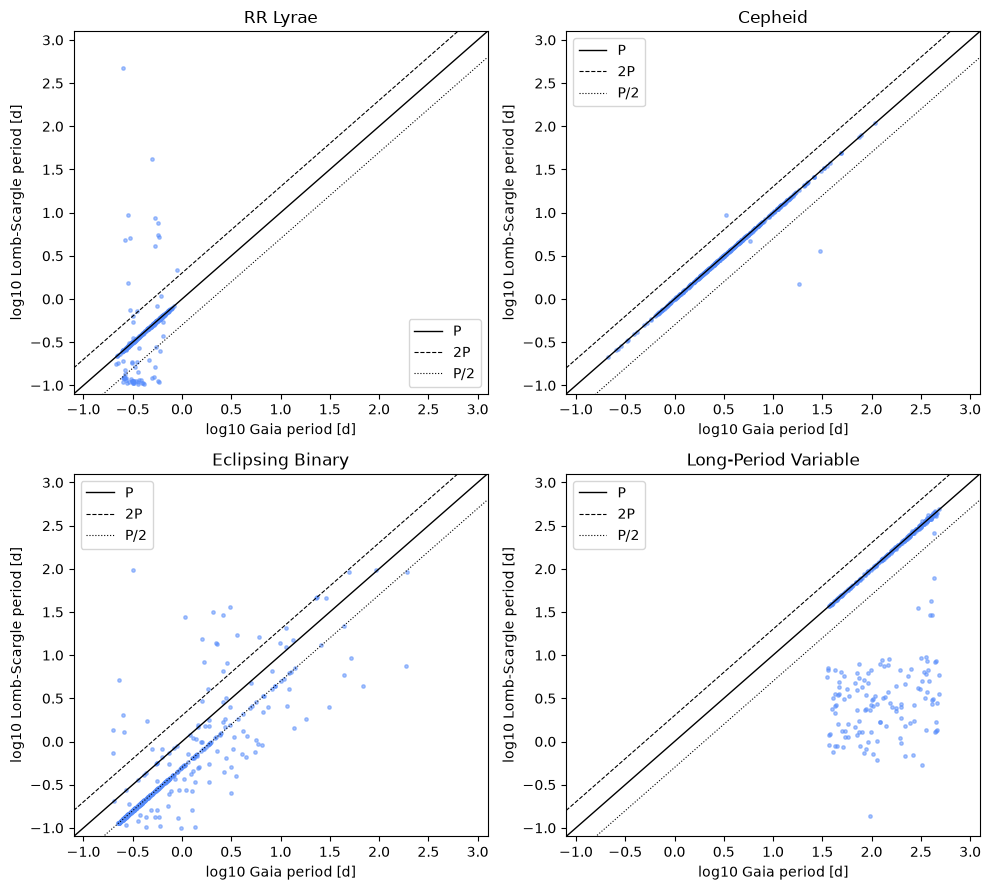

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(10, 9))
limits = np.array([-1.1, 3.1])

for ax, class_name in zip(axes.ravel(), CLASSES):
    part = eligible.loc[eligible["class_name"].eq(class_name)]

    ax.scatter(np.log10(part["gaia_period"]), np.log10(part["ls_period"]), s=6, alpha=0.5)
    ax.plot(limits, limits, "k-", linewidth=1, label="P")
    ax.plot(limits, limits + np.log10(2), "k--", linewidth=0.8, label="2P")
    ax.plot(limits, limits - np.log10(2), "k:", linewidth=0.8, label="P/2")

    ax.set(
        xlim=limits, ylim=limits, title=class_name,
        xlabel="log10 Gaia period [d]", ylabel="log10 Lomb-Scargle period [d]",
    )
    ax.legend()

fig.tight_layout()
fig.savefig(PLOT_ROOT / "period_validation_scatter.png", dpi=160, bbox_inches="tight")
plt.show()

## Period Ratio Histogram

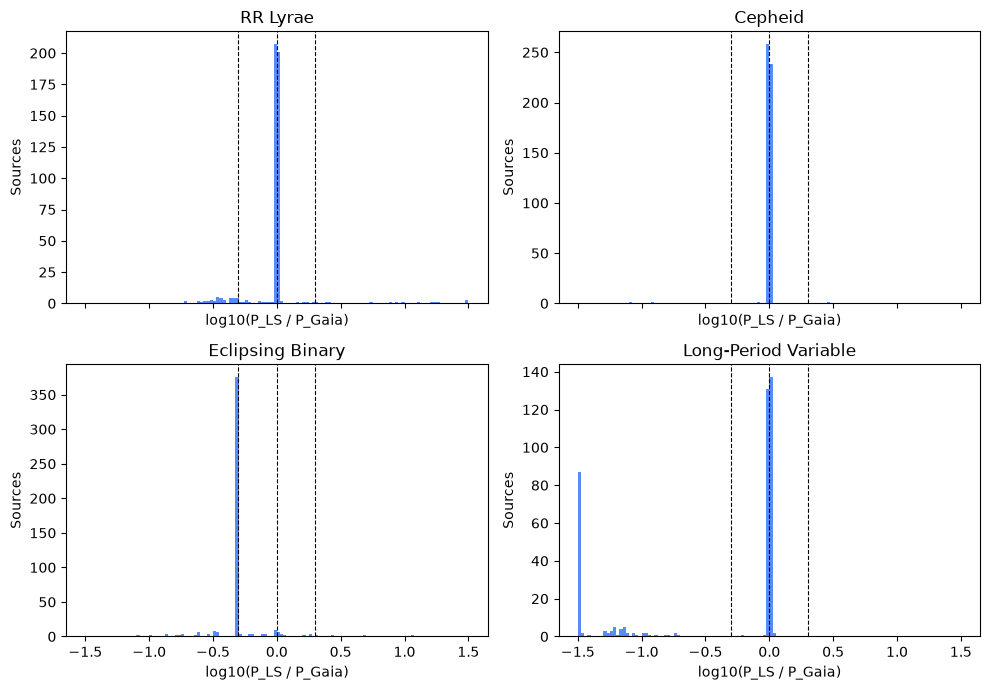

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7), sharex=True)

for ax, class_name in zip(axes.ravel(), CLASSES):
    part = eligible.loc[eligible["class_name"].eq(class_name)]

    ax.hist(np.log10(part["period_ratio"]).clip(-1.5, 1.5), bins=np.linspace(-1.5, 1.5, 121))

    for ratio in [0.5, 1, 2]:
        ax.axvline(np.log10(ratio), color="black", linestyle="--", linewidth=0.8)

    ax.set(title=class_name, xlabel="log10(P_LS / P_Gaia)", ylabel="Sources")

fig.tight_layout()
fig.savefig(PLOT_ROOT / "period_ratio_histogram.png", dpi=160, bbox_inches="tight")
plt.show()

## Phase-Folded Examples

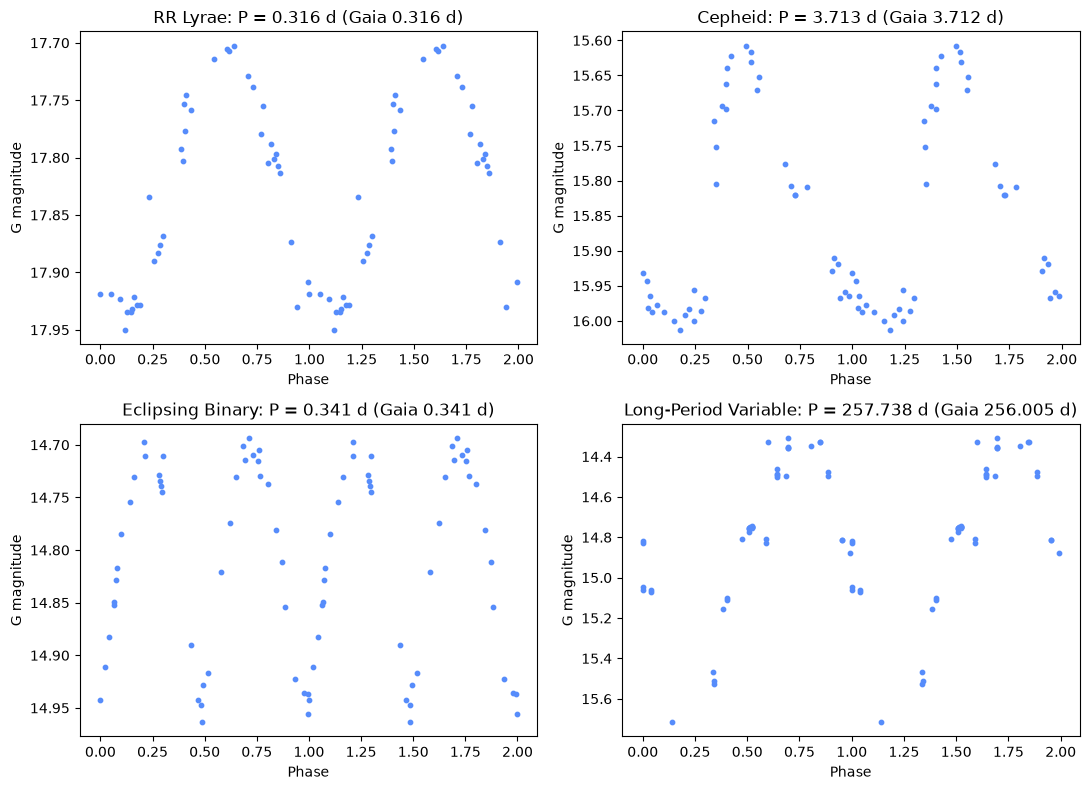

LPVs with Gaia-validated LS period: 269 of 500


In [6]:
photometry = pd.read_csv(
    CLEAN_FILE, usecols=["source_id", "g_transit_time", "g_transit_mag"]
)

fig, axes = plt.subplots(2, 2, figsize=(11, 8))

for ax, class_name in zip(axes.ravel(), CLASSES):
    part = eligible.loc[
        eligible["class_name"].eq(class_name)
        & eligible["period_status"].isin(["exact", "half"])
    ].sort_values("n_obs")

    star = part.iloc[len(part) // 2]
    period = star["ls_period"] * (2 if star["period_status"] == "half" else 1)

    curve = photometry.loc[photometry["source_id"].eq(star["source_id"])]
    phase = ((curve["g_transit_time"] - curve["g_transit_time"].min()) / period) % 1

    ax.scatter(phase, curve["g_transit_mag"], s=10, color="C0")
    ax.scatter(phase + 1, curve["g_transit_mag"], s=10, color="C0")
    ax.invert_yaxis()
    ax.set(
        title=f"{class_name}: P = {period:.3f} d (Gaia {star['gaia_period']:.3f} d)",
        xlabel="Phase", ylabel="G magnitude",
    )

fig.tight_layout()
fig.savefig(PLOT_ROOT / "revised_phase_folded_examples.png", dpi=160, bbox_inches="tight")
plt.show()

lpv = qc.loc[qc["class_name"].eq("Long-Period Variable")]
print("LPVs with Gaia-validated LS period:", lpv["period_status"].eq("exact").sum(), "of", len(lpv))

Gaia Label Confidence

In [9]:
Gaia.ROW_LIMIT = -1

sources = pd.read_csv(SOURCE_FILE)
ids = Table({"source_id": sources["source_id"].to_numpy(dtype="int64")})

candidates = {
    class_name: int(
        Gaia.launch_job(
            f"SELECT COUNT(*) AS n FROM gaiadr3.{table} AS variability "
            f"WHERE {PERIOD_FILTERS[class_name]}"
        ).get_results()["n"][0]
    )
    for class_name, table in CLASS_TABLES.items()
}

scores = Gaia.launch_job(
    "SELECT c.source_id, c.best_class_name, c.best_class_score FROM tap_upload.ids AS s "
    "JOIN gaiadr3.vari_classifier_result AS c ON s.source_id = c.source_id",
    upload_resource=ids, upload_table_name="ids",
).get_results().to_pandas()

print(scores["best_class_name"].value_counts())

labels = sources[["source_id", "class_name"]].merge(
    scores, on="source_id", how="left", validate="one_to_one"
)
labels["matches_general_class"] = (
    labels["best_class_name"].eq(labels["class_name"].map(GENERAL_CLASS))
)
labels.to_csv(LABEL_FILE, index=False)

summary = labels.groupby("class_name").agg(
    selected=("source_id", "size"),
    matches_general_class=("matches_general_class", "sum"),
    score_median=("best_class_score", "median"),
).reindex(CLASSES)
summary["candidates_before_downsampling"] = pd.Series(candidates)
summary.to_csv(SUMMARY_FILE)

display(summary)

best_class_name
ECL    501
LPV    500
RR     499
CEP    499
Name: count, dtype: int64


,selected,matches_general_class,score_median,candidates_before_downsampling
class_name,,,,
RR Lyrae,500,499,0.524765,271779
Cepheid,500,499,0.506386,14987
Eclipsing Binary,500,500,0.660146,2184477
Long-Period Variable,500,500,0.870233,392240
